In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
"""
   Changing the directory to the required working directory. Please change the
   path accordingly where this source file save on the Google drive.
"""
%cd '/content/drive/My Drive/2_PHDWork/1_Objective-I/4_Enlargement_Strategy/1_ComparisonStudy/'

/content/drive/My Drive/2_PHDWork/1_Objective-I/4_Enlargement_Strategy/1_ComparisonStudy


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import os
import seaborn as sns

In [ ]:
"""
  The path to which the results (plots) to be saved
"""
outpath = "./results/"

In [ ]:
"""
  Method to get the subscript font of a given character.

  Parameters:
     x : the character to be converted to subscript font.

  Returns:
     The subscript font of the given character.
"""
def get_sub(x):
  normal = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789+-=()"
  sub_s = "ₐ₈CDₑբGₕᵢⱼₖₗₘₙₒₚQᵣₛₜᵤᵥwₓᵧZₐ♭꜀ᑯₑբ₉ₕᵢⱼₖₗₘₙₒₚ૧ᵣₛₜᵤᵥwₓᵧ₂₀₁₂₃₄₅₆₇₈₉₊₋₌₍₎"
  res = x.maketrans(''.join(normal), ''.join(sub_s))
  return x.translate(res)

	-------------Average Accuracy ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [99.58, 99.71, 99.67, 99.55, 99.4]
	-------------Average Dice Coefficient ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [0.989, 0.992, 0.991, 0.988, 0.984]
	-------------Average IOU ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [0.978, 0.984, 0.982, 0.977, 0.969]
	-------------Average TPR ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [0.9862, 0.9943, 0.9976, 0.9986, 0.9989]
	-------------Average FPR ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [0.0018, 0.0023, 0.0036, 0.0056, 0.0077]
	-------------Average Housdroff Distance ---------------------
[0.0, 0.25, 0.5, 0.75, 1.0]: [230.1, 225.8, 222.33, 218.97, 215.7]


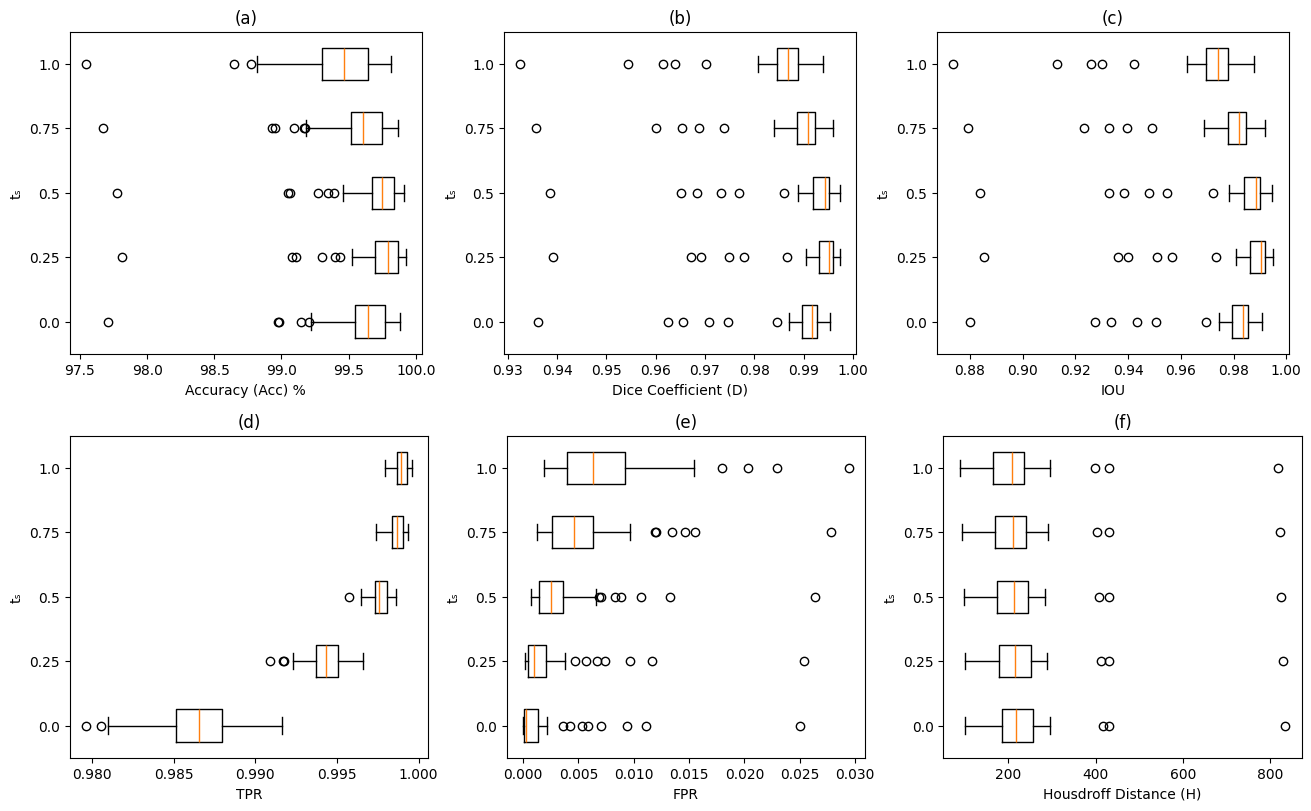

In [ ]:
"""
  Methods to generate the Range of evaluation metrics for PANDA dataset for
  different values of shift factor t
"""
def plot_t_parameter_box_plot(dfs,ts,fig1,fig2):
  gs1 = GridSpec(1, 3, figure=fig1)
  ax1 = fig1.add_subplot(gs1[0, 0])
  ax2 = fig1.add_subplot(gs1[0, 1])
  ax3 = fig1.add_subplot(gs1[0, 2])

  gs2 = GridSpec(1, 3, figure=fig2)
  ax4 = fig2.add_subplot(gs2[0, 0])
  ax5 = fig2.add_subplot(gs2[0, 1])
  ax6 = fig2.add_subplot(gs2[0, 2])

  para_label = 't{}'.format(get_sub('s'))
  limit = len(dfs)

  # Comparing Accuracy
  data = []
  labels = []
  avg = []
  values = dfs[0]['s_accuracy'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),2))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_accuracy'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),2))
    labels.append(f'{ts[i]}')

  ax1.boxplot(data,vert=False)
  ax1.set_yticklabels(labels)
  ax1.set_ylabel(para_label)
  ax1.set_xlabel('Accuracy (Acc) %')
  ax1.set_title('(a)')
  print(f'\t-------------Average Accuracy ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  # Comparing Dice Coefficient
  data = []
  labels = []
  avg = []

  values = dfs[0]['s_dice'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),3))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_dice'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),3))
    labels.append(f'{ts[i]}')

  ax2.boxplot(data,vert=False)
  ax2.set_yticklabels(labels)
  ax2.set_ylabel(para_label)
  ax2.set_xlabel('Dice Coefficient (D)')
  ax2.set_title('(b)')
  print(f'\t-------------Average Dice Coefficient ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  # Comparing IOU
  data = []
  labels = []
  avg = []

  values = dfs[0]['s_iou'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),3))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_iou'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),3))
    labels.append(f'{ts[i]}')

  ax3.boxplot(data,vert=False)
  ax3.set_yticklabels(labels)
  ax3.set_ylabel(para_label)
  ax3.set_xlabel('IOU')
  ax3.set_title('(c)')
  print(f'\t-------------Average IOU ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  # Comparing TPR
  data = []
  labels = []
  avg = []

  values = dfs[0]['s_tpr'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),4))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_tpr'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),4))
    labels.append(f'{ts[i]}')

  # ax4.set_xscale('log')
  ax4.boxplot(data,vert=False)
  ax4.set_yticklabels(labels)
  ax4.set_ylabel(para_label)
  ax4.set_xlabel('TPR')
  ax4.set_title('(d)')
  print(f'\t-------------Average TPR ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  # Comparing FPR
  data = []
  labels = []
  avg = []

  values = dfs[0]['s_fpr'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),4))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_fpr'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),4))
    labels.append(f'{ts[i]}')

  # ax4.set_xscale('log')
  ax5.boxplot(data,vert=False)
  ax5.set_yticklabels(labels)
  ax5.set_ylabel(para_label)
  ax5.set_xlabel('FPR')
  ax5.set_title('(e)')
  print(f'\t-------------Average FPR ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  # Comparing Housdroff Distance
  data = []
  labels = []
  avg = []

  values = dfs[0]['s_hdit'].values.tolist()
  data.append(values)
  avg.append(round(sum(values)/len(values),2))
  labels.append(f'{0.00}')

  for i in range(limit):
    values = dfs[i]['m_hdit'].values.tolist()
    data.append(values)
    avg.append(round(sum(values)/len(values),2))
    labels.append(f'{ts[i]}')

  # ax4.set_xscale('log')
  ax6.boxplot(data,vert=False)
  ax6.set_yticklabels(labels)
  ax6.set_ylabel(para_label)
  ax6.set_xlabel('Housdroff Distance (H)')
  ax6.set_title('(f)')
  print(f'\t-------------Average Housdroff Distance ---------------------')
  print(f'{[0.0, 0.25, 0.5, 0.75, 1.0]}: {avg}')

  return

def generate_t_parameter_box_plot():
  f1 = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_25_C4.csv" # t = 0.25
  f2 = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_5_C4.csv"  # t = 0.5
  f3 = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_75_C4.csv" # t = 0.75
  f4 = "./log_files/Enlargment_FIMG_log_data_Level_0_T1_0_C4.csv"  # t = 1.0

  df1 = pd.read_csv(f1)
  df2 = pd.read_csv(f2)
  df3 = pd.read_csv(f3)
  df4 = pd.read_csv(f4)

  dfs = [df1,df2,df3,df4]
  ts = [0.25, 0.50, 0.75, 1.00]

  fig = plt.figure(layout="constrained",figsize=(13,8))
  # fig.suptitle("Proposed Method V/s Normal Scaling.")
  gs = GridSpec(2, 1, figure=fig)
  fig1 = fig.add_subfigure(gs[0,0])
  fig2 = fig.add_subfigure(gs[1,0])
  # fig2.suptitle(f'------------------------------------------------------------')

  plot_t_parameter_box_plot(dfs,ts,fig1,fig2)

  outfile = outpath + "Translation_Parameter_Comparison.pdf"
  plt.savefig(outfile, format='pdf')
  plt.show()
  return

generate_t_parameter_box_plot()

	-------------Average Accuracy---------------------
		Level-0 = 99.67
	-------------Average Dice Coefficient---------------------
		Level-0 = 0.99
	-------------Average IOU---------------------
		Level-0 = 0.98
	-------------Average TPR ---------------------
		Level-0 = 1.0
	-------------Average FPR ---------------------
		Level-0 = 0.0
	-------------Average Housdroff ---------------------
		Level-0 = 222.33


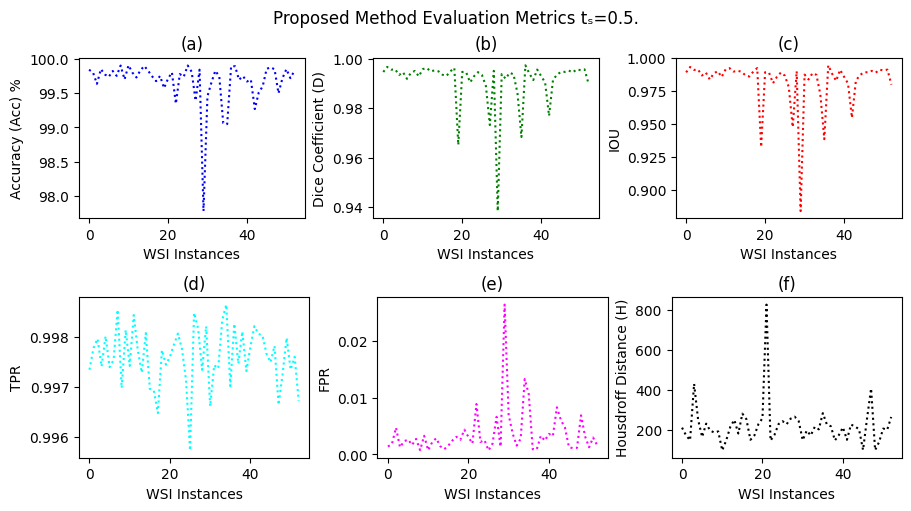

In [ ]:
"""
  Method to generate the evaluation metrics for the proposed method with t = 0.5
"""
def plot_area_box_plot(l0_df,fig1,fig2):
  gs1 = GridSpec(1, 3, figure=fig1)
  ax1 = fig1.add_subplot(gs1[0, 0])
  ax2 = fig1.add_subplot(gs1[0, 1])
  ax3 = fig1.add_subplot(gs1[0, 2])

  gs2 = GridSpec(1, 3, figure=fig2)
  ax4 = fig2.add_subplot(gs2[0, 0])
  ax5 = fig2.add_subplot(gs2[0, 1])
  ax6 = fig2.add_subplot(gs2[0, 2])

  # Computing the Accuracy
  l0_acc = l0_df['m_accuracy'].values.tolist()

  x = range(len(l0_acc))
  ax1.plot(x,l0_acc,color='blue',label='Level-0',linestyle='dotted')
  ax1.set_xlabel('WSI Instances')
  ax1.set_ylabel('Accuracy (Acc) %')
  # ax1.legend(fontsize="8")
  ax1.set_title('(a)')

  print(f'\t-------------Average Accuracy---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_acc)/len(l0_acc),2)}')

  # Computing Dice Coefficient
  l0_D = l0_df['m_dice'].values.tolist()

  ax2.plot(x,l0_D,color='green',label='Level-0',linestyle='dotted')
  ax2.set_xlabel('WSI Instances')
  ax2.set_ylabel('Dice Coefficient (D)')
  # ax2.legend(fontsize="8")
  ax2.set_title('(b)')

  print(f'\t-------------Average Dice Coefficient---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_D)/len(l0_D),2)}')

  # Computing IOU
  l0_J = l0_df['m_iou'].values.tolist()

  ax3.plot(x,l0_J,color='red',label='Level-0',linestyle='dotted')
  ax3.set_xlabel('WSI Instances')
  ax3.set_ylabel('IOU')
  # ax3.legend(fontsize="8")
  ax3.set_title('(c)')
  print(f'\t-------------Average IOU---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_J)/len(l0_J),2)}')

  # Computing TPR
  l0_tpr = l0_df['m_tpr'].values.tolist()
  ax4.plot(x,l0_tpr,color='cyan',label='Level-0',linestyle='dotted')
  ax4.set_xlabel('WSI Instances')
  ax4.set_ylabel('TPR')
  # ax3.legend(fontsize="8")
  ax4.set_title('(d)')
  print(f'\t-------------Average TPR ---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_tpr)/len(l0_tpr),2)}')

  # Computing FPR
  l0_fpr = l0_df['m_fpr'].values.tolist()
  ax5.plot(x,l0_fpr,color='magenta',label='Level-0',linestyle='dotted')
  ax5.set_xlabel('WSI Instances')
  ax5.set_ylabel('FPR')
  # ax3.legend(fontsize="8")
  ax5.set_title('(e)')
  print(f'\t-------------Average FPR ---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_fpr)/len(l0_fpr),2)}')

  # Computing Housdroff
  l0_mdit = l0_df['m_hdit'].values.tolist()
  ax6.plot(x,l0_mdit,color='black',label='Level-0',linestyle='dotted')
  ax6.set_xlabel('WSI Instances')
  ax6.set_ylabel('Housdroff Distance (H)')
  # ax3.legend(fontsize="8")
  ax6.set_title('(f)')
  print(f'\t-------------Average Housdroff ---------------------')
  print(f'\t\tLevel-0 = {round(sum(l0_mdit)/len(l0_mdit),2)}')

  return

def generate_area_and_performance_box_plot():
  l0_filename = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_5_C4.csv" # Convex hull of four contours
  l0_df = pd.read_csv(l0_filename)

  fig = plt.figure(layout="constrained",figsize=(9,5))
  title = 'Proposed Method Evaluation Metrics t{}=0.5.'.format(get_sub('s'))
  fig.suptitle(title)
  gs = GridSpec(2, 1, figure=fig)
  fig1 = fig.add_subfigure(gs[0,0])
  fig2 = fig.add_subfigure(gs[1,0])
  # fig2.suptitle(f'------------------------------------------------------------')

  plot_area_box_plot(l0_df,fig1,fig2)

  outfile = outpath + "Output_Performance.pdf"
  plt.savefig(outfile, format='pdf')
  plt.show()

generate_area_and_performance_box_plot()

/tmp/ipykernel_2561/1868024922.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Values', data=data, palette='Set2',ax=ax1)
/tmp/ipykernel_2561/1868024922.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Values', data=data1, palette='Set2',ax=ax2)
/tmp/ipykernel_2561/1868024922.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Category', y='Values', data=data2, palette='Set2',ax=ax3)
/tmp/ipykernel_2561/1868024922.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated an




Mean Accuracy: Proposed = 99.0855, Scaling: 98.9528
Mean Dice Coefficient: Proposed = 0.9786, Scaling: 0.9751
Mean IOU: Proposed = 0.9604, Scaling: 0.9541
Mean TPR: Proposed = 0.9764, Scaling: 0.9642
Mean FPR: Proposed = 0.0047, Scaling: 0.003
Mean Housdroff Distance: Proposed = 1821.6883, Scaling: 1826.6106


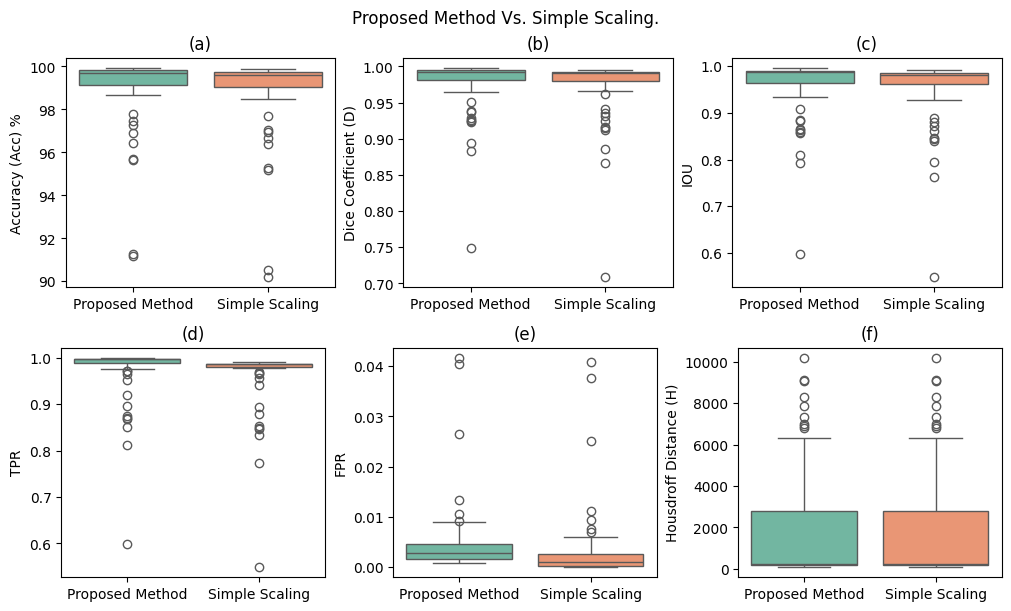

In [ ]:
"""
  Methods to generate the comparison of evaluation metrics for simple scaling
  and proposed method.
"""

def plot_box_plot(l0_df,fig1,fig2):
  gs1 = GridSpec(1, 3, figure=fig1)
  ax1 = fig1.add_subplot(gs1[0, 0])
  ax2 = fig1.add_subplot(gs1[0, 1])
  ax3 = fig1.add_subplot(gs1[0, 2])

  gs2 = GridSpec(1, 3, figure=fig2)
  ax4 = fig2.add_subplot(gs2[0, 0])
  ax5 = fig2.add_subplot(gs2[0, 1])
  ax6 = fig2.add_subplot(gs2[0, 2])

  # Comparing Accuracy
  acc1 = l0_df['m_accuracy'].values.tolist()
  acc2 = l0_df['s_accuracy'].values.tolist()
  limit = len(acc1)
  data = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': acc1 + acc2})
  sns.boxplot(x='Category', y='Values', data=data, palette='Set2',ax=ax1)
  ax1.set_xlabel('')
  ax1.set_ylabel('Accuracy (Acc) %')
  ax1.set_title('(a)')

  # Comparing Dice Coefficient
  dice1 = l0_df['m_dice'].values.tolist()
  dice2 = l0_df['s_dice'].values.tolist()
  limit = len(dice1)
  data1 = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': dice1 + dice2})
  sns.boxplot(x='Category', y='Values', data=data1, palette='Set2',ax=ax2)
  ax2.set_xlabel('')
  ax2.set_ylabel('Dice Coefficient (D)')
  ax2.set_title('(b)')

  # Comparing IOU
  iou1 = l0_df['m_iou'].values.tolist()
  iou2 = l0_df['s_iou'].values.tolist()
  limit = len(iou1)
  data2 = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': iou1 + iou2})
  sns.boxplot(x='Category', y='Values', data=data2, palette='Set2',ax=ax3)
  ax3.set_xlabel('')
  ax3.set_ylabel('IOU')
  ax3.set_title('(c)')

  # Comparing TPR
  tpr1 = l0_df['m_tpr'].values.tolist()
  tpr2 = l0_df['s_tpr'].values.tolist()
  limit = len(tpr1)
  data3 = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': tpr1 + tpr2})
  sns.boxplot(x='Category', y='Values', data=data3, palette='Set2',ax=ax4)
  ax4.set_xlabel('')
  ax4.set_ylabel('TPR')
  ax4.set_title('(d)')

  # Comparing FPR
  fpr1 = l0_df['m_fpr'].values.tolist()
  fpr2 = l0_df['s_fpr'].values.tolist()
  limit = len(fpr1)
  data4 = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': fpr1 + fpr2})
  sns.boxplot(x='Category', y='Values', data=data4, palette='Set2',ax=ax5)
  ax5.set_xlabel('')
  ax5.set_ylabel('FPR')
  ax5.set_title('(e)')

  # Comparing Housdroff distance
  hdit1 = l0_df['m_hdit'].values.tolist()
  hdit2 = l0_df['s_hdit'].values.tolist()
  limit = len(hdit1)
  data5 = pd.DataFrame({'Category': ['Proposed Method']*limit + ['Simple Scaling']*limit,
                     'Values': hdit1 + hdit2})
  sns.boxplot(x='Category', y='Values', data=data5, palette='Set2',ax=ax6)
  ax6.set_xlabel('')
  ax6.set_ylabel('Housdroff Distance (H)')
  ax6.set_title('(f)')

  print(f'\n\n')
  print(f'Mean Accuracy: Proposed = {round(np.mean(acc1),4)}, Scaling: {round(np.mean(acc2),4)}')
  print(f'Mean Dice Coefficient: Proposed = {round(np.mean(dice1),4)}, Scaling: {round(np.mean(dice2),4)}')
  print(f'Mean IOU: Proposed = {round(np.mean(iou1),4)}, Scaling: {round(np.mean(iou2),4)}')
  print(f'Mean TPR: Proposed = {round(np.mean(tpr1),4)}, Scaling: {round(np.mean(tpr2),4)}')
  print(f'Mean FPR: Proposed = {round(np.mean(fpr1),4)}, Scaling: {round(np.mean(fpr2),4)}')
  print(f'Mean Housdroff Distance: Proposed = {round(np.mean(hdit1),4)}, Scaling: {round(np.mean(hdit2),4)}')

  return


def generate_metric_comparison_box_plot():
  # l0_filename = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_5_C4.csv"
  l0_filename = "./log_files/proposed_method_results.csv"
  l0_df = pd.read_csv(l0_filename)

  fig = plt.figure(layout="constrained",figsize=(10,6))
  fig.suptitle("Proposed Method Vs. Simple Scaling.")
  gs = GridSpec(2, 1, figure=fig)
  fig1 = fig.add_subfigure(gs[0,0])
  fig2 = fig.add_subfigure(gs[1,0])
  # fig2.suptitle(f'------------------------------------------------------------')

  plot_box_plot(l0_df,fig1,fig2)

  outfile = outpath + "Metric_Comparison_New.pdf"
  plt.savefig(outfile, format='pdf')
  plt.show()
  return

generate_metric_comparison_box_plot()

Excel file './results/method_comparison_results.xlsx' generated successfully!
./results/PANDA_comparison_plot_for_methods.pdf


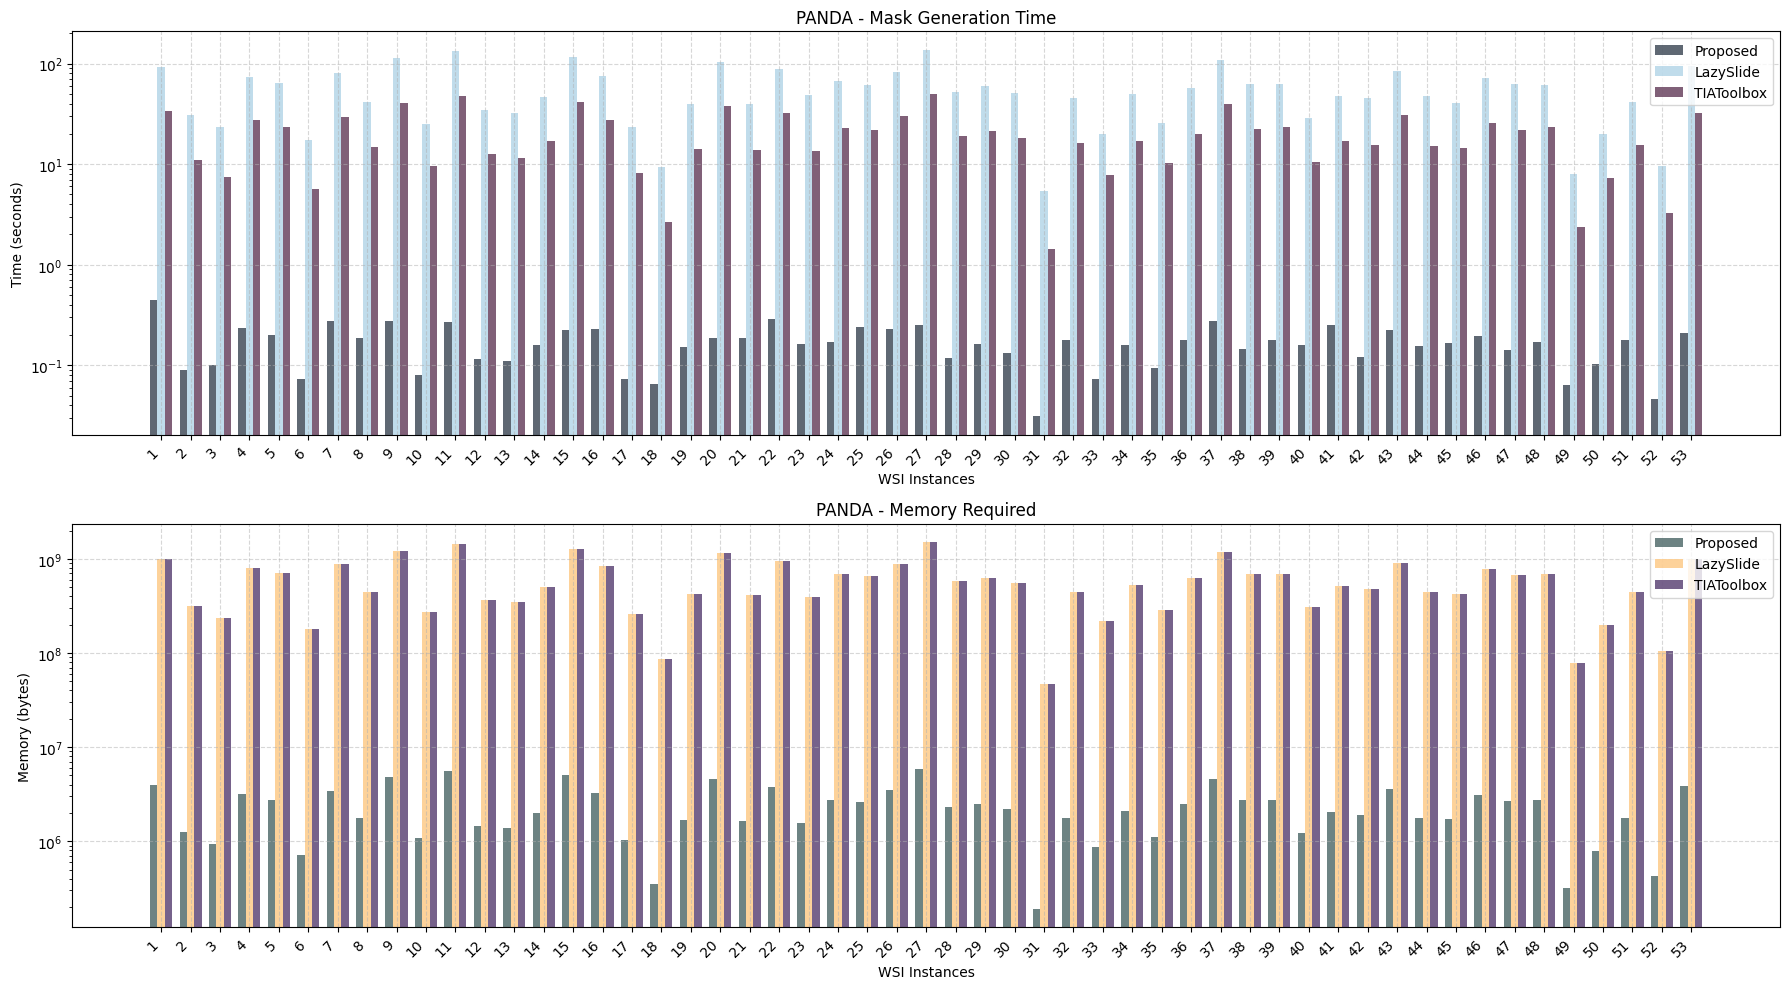

./results/CPTAC-CM_comparison_plot_for_methods.pdf


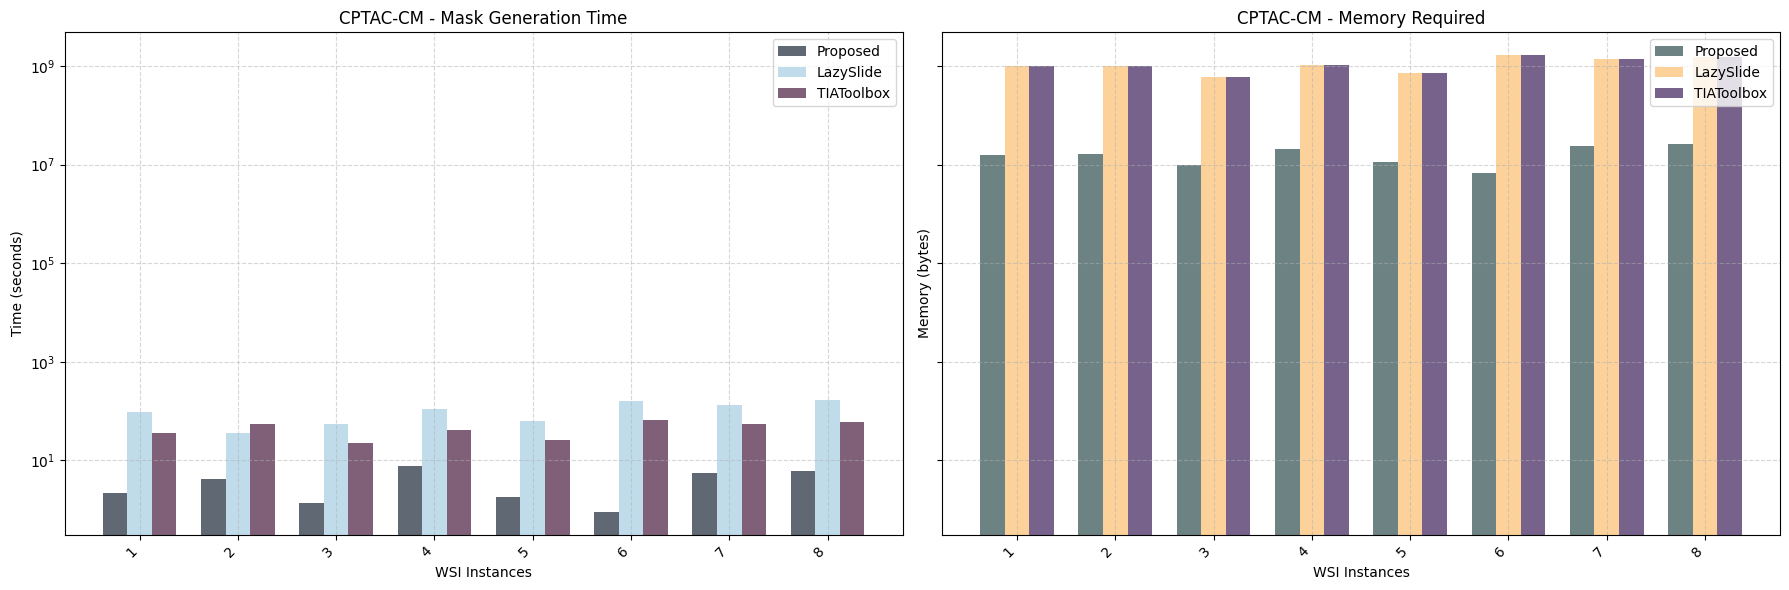

./results/CPTAC-UCEC_comparison_plot_for_methods.pdf


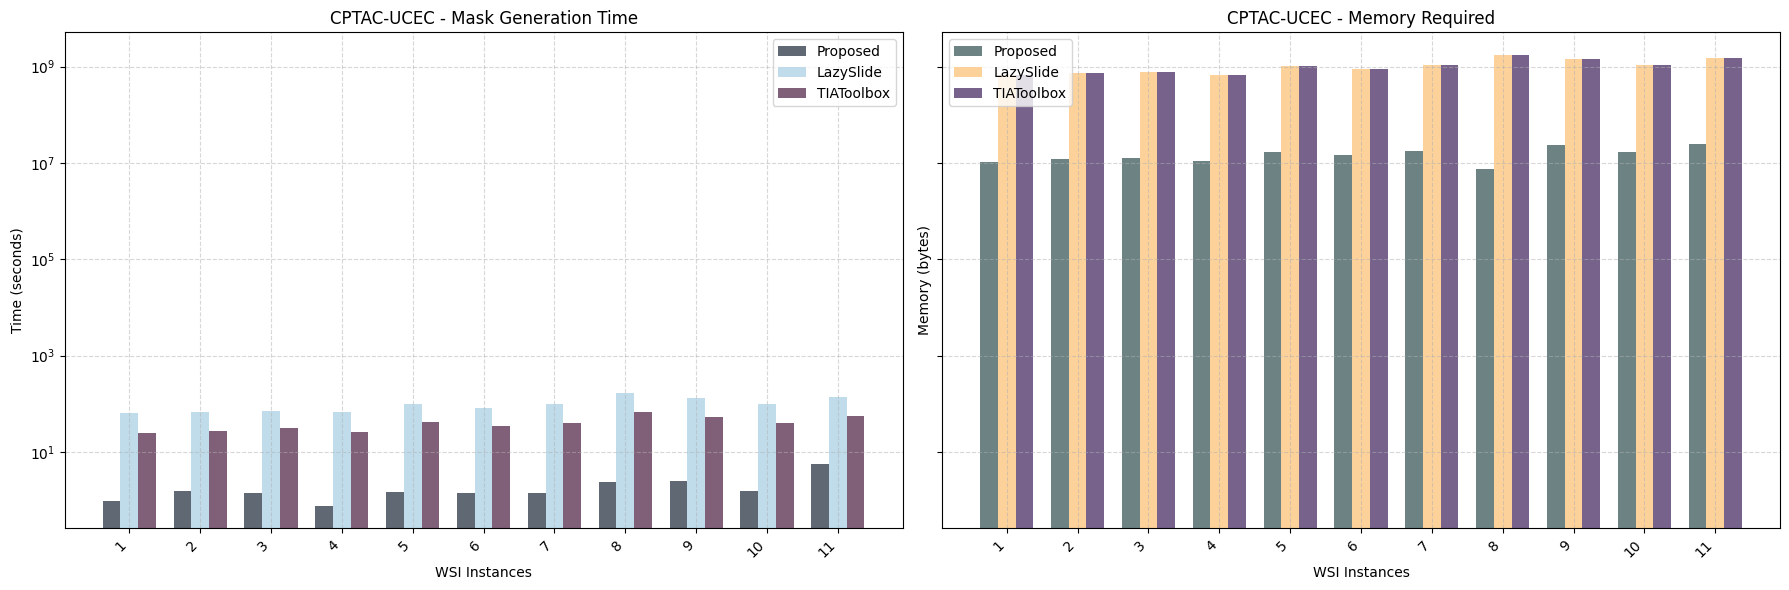

In [ ]:
# ===========================
# Tissue Segmentation Method comparison
# ===========================

class TissueSegmentationAnalysis:
    def __init__(self, proposed_file, lazyslide_file, tiatoolbox_file, output_excel):
        self.proposed_file = proposed_file
        self.lazyslide_file = lazyslide_file
        self.tiatoolbox_file = tiatoolbox_file
        self.output_excel = output_excel
        self.combined_df = None
        self.avg_df = None

    def load_and_prepare_data(self):
        """Load CSVs and compute mask generation times."""
        proposed_df = pd.read_csv(self.proposed_file)
        lazyslide_df = pd.read_csv(self.lazyslide_file)
        tiatoolbox_df = pd.read_csv(self.tiatoolbox_file)

        # Compute mask generation time
        proposed_df["mask_gen_time"] = (
            proposed_df["read_time"] +
            proposed_df["m_cntr_trans_time"] +
            proposed_df["m_msk_fill_time"]
        )
        lazyslide_df["mask_gen_time"] = lazyslide_df["org_msk_gen_time"]
        tiatoolbox_df["mask_gen_time"] = tiatoolbox_df["org_msk_gen_time"]

        # Add method column
        proposed_df["method"] = "Proposed"
        lazyslide_df["method"] = "LazySlide"
        tiatoolbox_df["method"] = "TIAToolbox"

        # Combine
        self.combined_df = pd.concat([proposed_df, lazyslide_df, tiatoolbox_df], ignore_index=True)

    def compute_averages(self):
        """Compute averages per dataset per method and save to Excel.
          For the Proposed method, memory values are adjusted before averaging."""
        df = self.combined_df.copy()

        # Adjust memory for Proposed method only
        df.loc[df["method"] == "Proposed", "m_mem_req"] = (
            df.loc[df["method"] == "Proposed", "m_mem_req"] +
            (df.loc[df["method"] == "Proposed", "t_row"] *
            df.loc[df["method"] == "Proposed", "t_col"] * 3)
        )

        metrics = ["m_accuracy", "m_dice", "m_iou", "m_hdit", "m_tpr", "m_fpr", "m_mem_req", "mask_gen_time"]
        self.avg_df = df.groupby(["dataset", "method"])[metrics].mean().reset_index()

        self.avg_df.to_excel(self.output_excel, index=False)
        print(f"Excel file '{self.output_excel}' generated successfully!")

        return


    def plot_dataset(self, dataset_name, layout="vertical"):
        """Generate grouped bar plots for a given dataset with log-scaled y-axis and sample numbers on both plots.
          For the Proposed method, memory values are adjusted by adding an extra field."""
        df = self.combined_df[self.combined_df["dataset"] == dataset_name].copy()
        df = df.reset_index(drop=True)
        df["sample_num"] = df.groupby("method").cumcount() + 1

        # Color schemes (replace with your preferred scheme)
        time_colors = {"Proposed":"#1b2838", "LazySlide":"#a6cee3", "TIAToolbox":"#4b1d3f"}
        mem_colors  = {"Proposed":"#2f4f4f", "LazySlide":"#fdbf6f", "TIAToolbox":"#3c1f5a"}

        methods = ["Proposed", "LazySlide", "TIAToolbox"]
        n_methods = len(methods)
        bar_width = 0.25
        indices = np.arange(df["sample_num"].nunique())

        if layout == "vertical":
            fig, axes = plt.subplots(2, 1, figsize=(18, 10), sharex=True)
        else:
            fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

        # Mask generation time plot
        ax_time = axes[0]
        for i, method in enumerate(methods):
            sub = df[df["method"] == method]
            ax_time.bar(indices + i*bar_width, sub["mask_gen_time"].values,
                        width=bar_width, label=method, color=time_colors[method], alpha=0.7)
        ax_time.set_title(f"{dataset_name} - Mask Generation Time")
        ax_time.set_ylabel("Time (seconds)")
        ax_time.set_yscale("log")
        ax_time.legend()
        ax_time.grid(True, linestyle="--", alpha=0.5)

        # Memory required plot
        ax_mem = axes[1]
        for i, method in enumerate(methods):
            sub = df[df["method"] == method].copy()

            # Adjust memory for Proposed method only
            if method == "Proposed":
                # For proposed method the memory required is the sum of the memory
                # for the thumbnail mask co-ordinates and the mask.
                sub["m_mem_req"] = sub["m_mem_req"] + (sub["t_row"]*sub["t_col"]*3)

            ax_mem.bar(indices + i*bar_width, sub["m_mem_req"].values,
                      width=bar_width, label=method, color=mem_colors[method], alpha=0.7)
        ax_mem.set_title(f"{dataset_name} - Memory Required")
        ax_mem.set_ylabel("Memory (bytes)")
        ax_mem.set_yscale("log")
        ax_mem.legend()
        ax_mem.grid(True, linestyle="--", alpha=0.5)

        # X-axis formatting
        tick_positions = indices + bar_width*(n_methods-1)/2
        if layout == "vertical":
            ax_time.set_xlabel("WSI Instances")
            ax_time.set_xticks(tick_positions)
            ax_time.set_xticklabels(indices+1, rotation=45, ha="right")
            ax_time.tick_params(labelbottom=True)

            ax_mem.set_xlabel("WSI Instances")
            ax_mem.set_xticks(tick_positions)
            ax_mem.set_xticklabels(indices+1, rotation=45, ha="right")
        else:
            ax_time.set_xlabel("WSI Instances")
            ax_mem.set_xlabel("WSI Instances")
            ax_time.set_xticks(tick_positions)
            ax_mem.set_xticks(tick_positions)
            ax_time.set_xticklabels(indices+1, rotation=45, ha="right")
            ax_mem.set_xticklabels(indices+1, rotation=45, ha="right")

        plt.tight_layout()
        # Save figure as PDF with dataset-specific name
        outfile = outpath + f"{dataset_name}_comparison_plot_for_methods.pdf"
        print(f'{outfile}')
        plt.savefig(outfile, dpi=300, bbox_inches="tight")
        plt.show()

        return

def main_generate_method():
    # Initialize analysis object
    analysis = TissueSegmentationAnalysis(
        "./log_files/proposed_method_results.csv",
        "./log_files/lazyslide_method_results.csv",
        "./log_files/tiatoolbox_method_results.csv",
        outpath + "method_comparison_results.xlsx"
    )

    # Run workflow
    analysis.load_and_prepare_data()
    analysis.compute_averages()

    # Generate figures
    analysis.plot_dataset("PANDA", layout="vertical")
    analysis.plot_dataset("CPTAC-CM", layout="horizontal")
    analysis.plot_dataset("CPTAC-UCEC", layout="horizontal")

main_generate_method()

In [ ]:
"""
  Methods to generate the memory and time comparison plot for the proposed
  method and the Otsu method on PANDA dataset.
"""
def plot_memory_and_time_comparison_plot(l0_df,l0_ots_df,fig1,fig2):
  gs1 = GridSpec(1, 1, figure=fig1)
  ax1 = fig1.add_subplot(gs1[0, 0])

  gs2 = GridSpec(1, 1, figure=fig2)
  ax2 = fig2.add_subplot(gs2[0, 0])

  # Plotting Mask Generation Time Comparison
  m_l0_rd_tm = l0_df['read_time'].values
  m_l0_tr_tm = l0_df['m_cntr_trans_time'].values
  m_l0_mk_tm = l0_df['m_msk_fill_time'].values
  m_l0_time = (m_l0_tr_tm + m_l0_mk_tm + m_l0_rd_tm).tolist()
  l0_ots_org_tm = l0_ots_df['org_msk_gen_time'].values.tolist()

  barWidth = 0.20
  # Set position of bar on X axis
  br1 = np.arange(53)
  br2 = [x + barWidth for x in br1]
  br3 = [x + barWidth for x in br2]
  x_pos = [br1,br2,br3]
  # col = ['blue','darkgoldenrod','cyan']
  # col = ['blue','black','cyan']
  col = ['darkgoldenrod','blue','cyan']
  div = (1)
  y_t = (27000000/div)

  # Ploting the L0 time of proposed method
  data_pnts = []
  for co in m_l0_time:
    data_pnts.append(((co * 8)/div))
  ax1.bar(x_pos[0], data_pnts, color = col[0], width = barWidth, edgecolor ='grey',
            label ='Proposed Method')

  # Ploting the L0 time of Otsu
  data_pnts = []
  for co in l0_ots_org_tm:
    data_pnts.append(((co * 8)/div))
  ax1.bar(x_pos[1], data_pnts, color = col[1], width = barWidth, edgecolor ='grey',
            label ='Otsu Method')

  ax1.set_title('Mask Generation Time')
  ax1.set_yscale('log')
  ax1.set_xlabel('Data Instances', fontweight ='bold', fontsize = 8)
  ax1.set_ylabel('Mask Generation Time (seconds)', fontweight ='bold', fontsize = 8)
  ax1.set_xticks([r + barWidth for r in range(53)],
        ['1', '2', '3', '4', '5','6','7','8','9','10','11','12','13','14','15',
         '16','17','18','19','20','21','22','23','24','25','26','27','28','29',
         '30','31','32','33','34','35','36','37','38','39','40','41','42','43',
         '44','45','46','47','48','49','50','51','52','53'])
  ax1.legend()

  print(f'\t-------------Average Mask Generation Time ---------------------')
  print(f'\t\tProposed = {round(sum(m_l0_time)/len(m_l0_time),4)}')
  print(f'\t\tOtsu = {round(sum(l0_ots_org_tm)/len(l0_ots_org_tm),4)}')

  # Plotting Memory Comparison
  l0_cor_mem = l0_df['m_mem_req'].values
  l0_t_row = l0_df['t_row'].values
  l0_t_col= l0_df['t_col'].values
  l0_mem_req = (l0_cor_mem + (l0_t_row * l0_t_col *3)).tolist()
  l0_oth_mem = l0_df['o_mem_req'].values.tolist()

  barWidth = 0.20
  # Set position of bar on X axis
  br1 = np.arange(53)
  br2 = [x + barWidth for x in br1]
  x_pos = [br1,br2]
  # col = ['blue','darkgoldenrod','cyan']
  # col = ['blue','black','cyan']
  col = ['darkgoldenrod','blue']
  div = (1)
  y_t = (27000000/div)

  # Ploting the L0 memory of proposed method
  data_pnts = []
  for co in l0_mem_req:
    data_pnts.append(((co * 8)/div))
  ax2.bar(x_pos[0], data_pnts, color = col[0], width = barWidth, edgecolor ='grey',
            label ='Proposed Method')

  # Ploting the L0 memory of Other methods
  data_pnts = []
  for co in l0_oth_mem:
    data_pnts.append(((co * 8)/div))
  ax2.bar(x_pos[1], data_pnts, color = col[1], width = barWidth, edgecolor ='grey',
            label ='Ostu Method')

  ax2.set_title('Memory Requirement')
  ax2.set_yscale('log')
  ax2.set_xlabel('Data Instances', fontweight ='bold', fontsize = 8)
  ax2.set_ylabel('Memory Used (bytes)', fontweight ='bold', fontsize = 8)
  ax2.set_xticks([r + barWidth for r in range(53)],
        ['1', '2', '3', '4', '5','6','7','8','9','10','11','12','13','14','15',
         '16','17','18','19','20','21','22','23','24','25','26','27','28','29',
         '30','31','32','33','34','35','36','37','38','39','40','41','42','43',
         '44','45','46','47','48','49','50','51','52','53'])
  ax2.legend()

  print(f'\t-------------Average Memory ---------------------')
  print(f'\t\tProposed = {round(sum(l0_mem_req)/len(l0_mem_req),2)}')
  print(f'\t\tOtsu = {round(sum(l0_oth_mem)/len(l0_oth_mem),2)}')

  return

def generate_memory_and_time_comparison_plot():
  l0_filename = "./log_files/Enlargment_FIMG_log_data_Level_0_T0_5_C4.csv"
  l0_Ots_filename = "./log_files/Otsu_log_data_full_image_Level_0.csv"

  l0_df = pd.read_csv(l0_filename)
  l0_ots_df = pd.read_csv(l0_Ots_filename)

  fig = plt.figure(layout="constrained",figsize=(13,8))
  # fig.suptitle("Proposed Method V/s Normal Scaling.")
  gs = GridSpec(2, 1, figure=fig)
  fig1 = fig.add_subfigure(gs[0,0])
  fig2 = fig.add_subfigure(gs[1,0])
  # fig2.suptitle(f'------------------------------------------------------------')

  plot_memory_and_time_comparison_plot(l0_df,l0_ots_df,fig1,fig2)

  outfile = outpath + "Time_Memory_Comparison.pdf"
  plt.savefig(outfile, format='pdf')
  plt.show()
  return

generate_memory_and_time_comparison_plot()